# Донавчання моделі Qwen3 для перетворення природної мови на SQL-запити

В процесі виконання, модель `Qwen3-1.7B` донавчається для перетворення питань природною мовою на SQL-запити за заданою схемою бази даних. Для донавчання використовується датасет Spider: [`SuperMax991/spider-text2sql`](https://huggingface.co/datasets/SuperMax991/spider-text2sql).

## 1.1. Задача

Аналітики та менеджери часто знають, що саме їм потрібно дізнатися з бази даних, але не навчені писати SQL. Мета полягає в автоматичному перетворенні питання, написаного природною мовою, на SQL-запит, який можна одразу виконати в базі даних. Підхід зменшує залежність від розробників та аналітиків під час типових вибірок і прискорює роботу з даними.

Модель отримує схему бази даних і питання, а повертає лише SQL-запит:
```
Schema: head: head_ID (number), name (text), born_state (text), age (number) | department: Department_ID (number), Name (text), ...
Question: How many heads of the departments are older than 56 ?
```
```sql
SELECT count(*) FROM head WHERE age > 56
```

In [ ]:
%pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "bitsandbytes" "datasets" "accelerate"
%pip uninstall -q -y torchao

In [ ]:
import os
import gc
import json
import random
import re
import sqlite3
import time
from collections import Counter
from functools import lru_cache
import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from IPython.display import display
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer
from trl import SFTConfig, SFTTrainer

assert torch.cuda.is_available(), "Для цього ноутбука потрібна GPU"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Пам'ять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Пам'ять GPU: 15.6 GB


## 1.2. Модель і дані

### 1.2.1. Інструкції для моделі

In [ ]:
TASK_INSTRUCTION = "You translate a question written in natural language into a single SQLite SQL query for the given database schema."
SHORT_PROMPT = "Translate the question into an SQL query for the given database schema. Reply with SQL only."

### 1.2.2. Формат даних

In [ ]:
SCHEMA_FORMAT = "The database schema is given as: table: column (type), column (type) | table: column (type), ..."
DOMAIN_RULES = [
    "Use only tables and columns that exist in the schema. Never invent new ones.",
    "Reply with exactly one SQL query: no explanations, no comments, no markdown.",
    "'How many' means count(*); 'average', 'total', 'maximum' and 'minimum' mean avg, sum, max and min.",
    "'The most', 'the highest', 'the largest' with a single answer: ORDER BY column DESC LIMIT 1 (ASC for 'the least', 'the lowest', 'the smallest').",
    "When two or more tables are used, join them with JOIN ... ON and give them the aliases T1, T2, T3 in order of appearance.",
    "Conditions on aggregates go to HAVING, grouping uses GROUP BY on the key column.",
    "'Both ... and' about different groups of the same column uses INTERSECT, 'either ... or' uses UNION, 'but not' and 'never' use EXCEPT or NOT IN with a subquery.",
    "Copy string values from the question as they are, in quotes: WHERE name = 'Alabama'.",
    "Do not add columns that were not asked for and do not add LIMIT unless a single or top-N answer is requested.",
]

### 1.2.3. Датасет

Обраний для задачі датасет Spider має таке представлення:
- `db_id` - назва бази даних.
- `question` - питання природною мовою.
- `query` - еталонний SQL-запит.
- `db_schema` - компактний опис схеми у форматі `table: col (type), col (type) | table: ...`.

In [ ]:
spider = load_dataset("SuperMax991/spider-text2sql")
print(spider)

df_spider = spider["train"].to_pandas()[["db_id", "question", "query", "db_schema"]]
per_db = df_spider["db_id"].value_counts()
print(f"\nБаз даних: {len(per_db)}, прикладів на одну базу: від {per_db.min()} до {per_db.max()}")
print(f"Довжина схеми в символах: середня {df_spider['db_schema'].str.len().mean():.0f}, максимум {df_spider['db_schema'].str.len().max()}")
display(df_spider.drop(columns="db_schema").sample(8, random_state=42))

README.md:   0%|          | 0.00/3.68k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.20MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  202kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1659 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['db_id', 'question', 'query', 'db_schema', 'question_toks'],
        num_rows: 7000
    })
    test: Dataset({
        features: ['db_id', 'question', 'query', 'db_schema', 'question_toks'],
        num_rows: 1659
    })
})

Баз даних: 140, прикладів на одну базу: від 7 до 170
Довжина схеми в символах: середня 712, максимум 5811


,db_id,question,query
6500,scientist_1,"What are the names of the scientists, and how ...","SELECT count(*) , T1.name FROM scientists AS ..."
2944,sakila_1,Find all the payment dates for the payments wi...,SELECT payment_date FROM payment WHERE amount ...
2024,gas_company,"For each company id, what are the companies an...","SELECT T2.company , count(*) FROM station_com..."
263,musical,Who is the nominee who has been nominated for ...,SELECT Nominee FROM musical GROUP BY Nominee O...
4350,tracking_grants_for_research,How many staff does each project has? List the...,"SELECT T1.project_id , count(*) FROM Project_..."
3424,hr_1,Return all information about employees with sa...,SELECT * FROM employees WHERE salary BETWEEN 8...
6748,activity_1,How many male and female assistant professors ...,"SELECT sex , count(*) FROM Faculty WHERE rank..."
6215,roller_coaster,Show the names of countries that have more tha...,SELECT T1.Name FROM country AS T1 JOIN roller_...


### 1.2.4. Ручний тестовий набір

In [ ]:
MANUAL_SCHEMAS = {
    "pc_shop": "customers: customer_id (number), name (text), city (text), email (text) | "
               "products: product_id (number), name (text), category (text), price (number), stock (number) | "
               "orders: order_id (number), customer_id (number), order_date (text), total_amount (number) | "
               "order_items: order_id (number), product_id (number), quantity (number)",
    "library": "books: book_id (number), title (text), author (text), year (number), genre (text) | "
               "members: member_id (number), name (text), join_year (number) | "
               "loans: loan_id (number), book_id (number), member_id (number), loan_date (text), returned (text)",
}

MANUAL_TEST = [
    ("pc_shop", "How many customers are there?",
     "SELECT count(*) FROM customers"),
    ("pc_shop", "List the names of products that cost more than 1000.",
     "SELECT name FROM products WHERE price > 1000"),
    ("pc_shop", "What is the average price of products in the category 'GPU'?",
     "SELECT avg(price) FROM products WHERE category = 'GPU'"),
    ("pc_shop", "Show the names of customers who live in Kyiv in alphabetical order.",
     "SELECT name FROM customers WHERE city = 'Kyiv' ORDER BY name"),
    ("pc_shop", "What is the name of the most expensive product?",
     "SELECT name FROM products ORDER BY price DESC LIMIT 1"),
    ("pc_shop", "How many orders did each customer make? List the customer name and the number of orders.",
     "SELECT T1.name , count(*) FROM customers AS T1 JOIN orders AS T2 ON T1.customer_id = T2.customer_id GROUP BY T1.customer_id"),
    ("pc_shop", "Find the names of customers who made more than 3 orders.",
     "SELECT T1.name FROM customers AS T1 JOIN orders AS T2 ON T1.customer_id = T2.customer_id GROUP BY T1.customer_id HAVING count(*) > 3"),
    ("pc_shop", "List the names of products that have never been ordered.",
     "SELECT name FROM products WHERE product_id NOT IN (SELECT product_id FROM order_items)"),
    ("pc_shop", "What are the different product categories and how many products does each of them have?",
     "SELECT category , count(*) FROM products GROUP BY category"),
    ("pc_shop", "What is the total quantity of the product 'RTX 4060' that was ordered?",
     "SELECT sum(T1.quantity) FROM order_items AS T1 JOIN products AS T2 ON T1.product_id = T2.product_id WHERE T2.name = 'RTX 4060'"),
    ("pc_shop", "Which cities have at least 5 customers?",
     "SELECT city FROM customers GROUP BY city HAVING count(*) >= 5"),
    ("pc_shop", "Show the names of customers who ordered a product from the category 'CPU' and also a product from the category 'GPU'.",
     "SELECT T1.name FROM customers AS T1 JOIN orders AS T2 ON T1.customer_id = T2.customer_id JOIN order_items AS T3 ON T2.order_id = T3.order_id JOIN products AS T4 ON T3.product_id = T4.product_id WHERE T4.category = 'CPU' "
     "INTERSECT SELECT T1.name FROM customers AS T1 JOIN orders AS T2 ON T1.customer_id = T2.customer_id JOIN order_items AS T3 ON T2.order_id = T3.order_id JOIN products AS T4 ON T3.product_id = T4.product_id WHERE T4.category = 'GPU'"),
    ("pc_shop", "What is the total amount of all orders placed in 2024?",
     "SELECT sum(total_amount) FROM orders WHERE order_date LIKE '2024%'"),
    ("library", "List the titles of books published after 2010, sorted by year.",
     "SELECT title FROM books WHERE year > 2010 ORDER BY year"),
    ("library", "How many different authors are there?",
     "SELECT count(DISTINCT author) FROM books"),
    ("library", "What are the names of members who have borrowed the book 'Dune'?",
     "SELECT T3.name FROM books AS T1 JOIN loans AS T2 ON T1.book_id = T2.book_id JOIN members AS T3 ON T2.member_id = T3.member_id WHERE T1.title = 'Dune'"),
    ("library", "Which genre has the most books?",
     "SELECT genre FROM books GROUP BY genre ORDER BY count(*) DESC LIMIT 1"),
    ("library", "Find the names of members who joined before 2020 and have never borrowed any book.",
     "SELECT name FROM members WHERE join_year < 2020 AND member_id NOT IN (SELECT member_id FROM loans)"),
    ("library", "Show the title of the oldest book.",
     "SELECT title FROM books ORDER BY year ASC LIMIT 1"),
    ("library", "How many loans have the returned value 'No'?",
     "SELECT count(*) FROM loans WHERE returned = 'No'"),
]

### 1.2.5. Запити поза задачею

In [ ]:
GENERAL_QUESTIONS = [
    "Поясни простими словами, що таке фотосинтез.",
    "Яка столиця Франції і чим вона відома?",
    "Чим відрізняється процесор від відеокарти?",
]

### 1.2.6. Допоміжні функції

In [ ]:
FEATURES = {
    "JOIN": r"\bjoin\b",
    "GROUP BY": r"\bgroup by\b",
    "HAVING": r"\bhaving\b",
    "ORDER BY": r"\border by\b",
    "LIMIT": r"\blimit\b",
    "вкладений запит": r"\(\s*select\b",
    "UNION / INTERSECT / EXCEPT": r"\b(union|intersect|except)\b",
}
FEATURE_NAMES = [*FEATURES, "простий"]

def sql_features(sql):
    s = sql.lower()
    found = {name for name, pattern in FEATURES.items() if re.search(pattern, s)}
    if not found:
        found.add("простий")
    return found

def parse_schema(db_schema):
    tables = {}
    for part in db_schema.split(" | "):
        name, _, columns = part.partition(": ")
        tables[name.strip()] = [c.strip() for c in re.findall(r"([^,]+?) \([^()]*\)", columns)]
    return tables

@lru_cache(maxsize=None)
def build_sqlite(db_schema):
    con = sqlite3.connect(":memory:")
    for table, columns in parse_schema(db_schema).items():
        columns = list(dict.fromkeys(c.lower() for c in columns))
        if not columns:
            continue
        try:
            cols = ", ".join('"' + c + '"' for c in columns)
            con.execute('CREATE TABLE "' + table + '" (' + cols + ')')
        except sqlite3.Error:
            continue
    return con

def valid_sql(db_schema, sql):
    if not sql:
        return False
    try:
        build_sqlite(db_schema).execute("EXPLAIN " + sql)
        return True
    except (sqlite3.Error, sqlite3.Warning):
        return False

def format_schema(db_schema):
    lines = []
    for part in db_schema.split(" | "):
        name, _, columns = part.partition(": ")
        lines.append(f"  {name.strip()}:")
        for column, dtype in re.findall(r"([^,]+?) \(([^()]*)\)", columns):
            lines.append(f"    - {column.strip()} ({dtype.strip()})")
    return "\n".join(lines)

def normalize_sql(sql):
    s = sql.strip().rstrip(";").strip()
    tokens = re.split(r"('(?:''|[^'])*')", s)
    for i in range(0, len(tokens), 2):
        part = tokens[i].lower()
        part = re.sub(r"\\s*([(),])\\s*", r"\\1", part)
        part = re.sub(r"\\s*(!=|<=|>=|=|<|>)\\s*", r" \\1 ", part)
        tokens[i] = re.sub(r"\\s+", " ", part).strip()
    return "".join(tokens)

def same_sql(a, b):
    return normalize_sql(a) == normalize_sql(b)

def build_user_message(example):
    return f"Schema: {example['schema']}\nQuestion: {example['question']}"

manual_examples = []
for db_id, question, query in MANUAL_TEST:
    schema = MANUAL_SCHEMAS[db_id]
    assert valid_sql(schema, query), f"Недопустимий еталонний запит у ручному прикладі: {question}"
    manual_examples.append({"db_id": db_id, "schema": schema, "question": question, "target": query, "features": sql_features(query)})

print(f"Конструкції в ручному наборі: { {n: sum(n in ex['features'] for ex in manual_examples) for n in FEATURE_NAMES} }")
print(f"Ручних тестових прикладів: {len(manual_examples)}")

Конструкції в ручному наборі: {'JOIN': 5, 'GROUP BY': 5, 'HAVING': 2, 'ORDER BY': 5, 'LIMIT': 3, 'вкладений запит': 2, 'UNION / INTERSECT / EXCEPT': 1, 'простий': 6}
Ручних тестових прикладів: 20


### 1.2.7. Підготовка прикладів

In [ ]:
def row_to_example(row):
    target = " ".join(row["query"].split()).rstrip(";").strip()
    return {"db_id": row["db_id"], "schema": row["db_schema"], "question": " ".join(row["question"].split()),
            "target": target, "features": sql_features(target)}

def load_examples(rows):
    seen, out = set(), []
    for row in rows:
        ex = row_to_example(row)
        key = (ex["db_id"], ex["question"].lower(), normalize_sql(ex["target"]))
        if key not in seen:
            seen.add(key)
            out.append(ex)
    return out

all_examples = load_examples(spider["train"])
gold_ok = [valid_sql(ex["schema"], ex["target"]) for ex in all_examples]
gold_share = sum(gold_ok) / len(gold_ok)
print(f"Прикладів після видалення дублікатів: {len(all_examples)}")
print(f"Еталонний SQL проходить перевірку на своїй схемі: {100 * gold_share:.1f}%")
assert gold_share > 0.8, "Перевірте parse_schema: більшість еталонних запитів не проходить перевірку"

all_examples = [ex for ex, ok in zip(all_examples, gold_ok) if ok]
print(f"Залишилось прикладів: {len(all_examples)}")

Прикладів після видалення дублікатів: 6991
Еталонний SQL проходить перевірку на своїй схемі: 100.0%
Залишилось прикладів: 6988


### 1.2.8. Тренувальний, валідаційний і тестовий набори

- Тренувальний набір - використовується для навчання моделі.
- Валідаційний набір - використовується для обчислення validation loss.
- Тестовий набір - використовується для оцінювання якості моделі до та після донавчання.

Набори розділяються за `db_id`.\
Кожна база даних потрапляє лише в один набір, що перевіряє здатність моделі працювати з новими схемами.

In [ ]:
N_VAL, N_TEST = 200, 500
VAL_DBS, TEST_DBS = 10, 15

db_ids = sorted({ex["db_id"] for ex in all_examples})
random.Random(42).shuffle(db_ids)
test_dbs = set(db_ids[:TEST_DBS])
val_dbs = set(db_ids[TEST_DBS:TEST_DBS + VAL_DBS])

train_examples = [ex for ex in all_examples if ex["db_id"] not in test_dbs | val_dbs]
val_examples = [ex for ex in all_examples if ex["db_id"] in val_dbs]
test_examples = [ex for ex in all_examples if ex["db_id"] in test_dbs]
for part in (train_examples, val_examples, test_examples):
    random.Random(42).shuffle(part)
val_examples, test_examples = val_examples[:N_VAL], test_examples[:N_TEST]

print(f"Бази даних - тренувальні: {len(db_ids) - VAL_DBS - TEST_DBS}, валідаційні: {VAL_DBS}, тестові: {TEST_DBS}")
print(f"Тренувальний: {len(train_examples)}, валідаційний: {len(val_examples)}, "
      f"тестовий: {len(test_examples)}, ручний: {len(manual_examples)}")

print("\nПриклади з тренувального набору:\n")
for ex in train_examples[:8]:
    print(f"База: {ex['db_id']}\n"
          f"Схема:\n{format_schema(ex['schema'])}\n"
          f"Питання: {ex['question']}\n"
          f"Еталон: {ex['target']}\n" + "-" * 60)

share = pd.Series({n: 100 * sum(n in ex["features"] for ex in train_examples) / len(train_examples)
                   for n in FEATURE_NAMES}).round(1)
display(share.to_frame("% прикладів із цією конструкцією (train)"))

Бази даних - тренувальні: 115, валідаційні: 10, тестові: 15
Тренувальний: 5717, валідаційний: 200, тестовий: 500, ручний: 20

Приклади з тренувального набору:

База: cre_Doc_Tracking_DB
Схема:
  Ref_Document_Types:
    - Document_Type_Code (text)
    - Document_Type_Name (text)
    - Document_Type_Description (text)
  Ref_Calendar:
    - Calendar_Date (time)
    - Day_Number (number)
  Ref_Locations:
    - Location_Code (text)
    - Location_Name (text)
    - Location_Description (text)
  Roles:
    - Role_Code (text)
    - Role_Name (text)
    - Role_Description (text)
  All_Documents:
    - Document_ID (number)
    - Date_Stored (time)
    - Document_Type_Code (text)
    - Document_Name (text)
    - Document_Description (text)
    - Other_Details (text)
  Employees:
    - Employee_ID (number)
    - Role_Code (text)
    - Employee_Name (text)
    - Gender_MFU (text)
    - Date_of_Birth (time)
    - Other_Details (text)
  Document_Locations:
    - Document_ID (number)
    - Location_Co

,% прикладів із цією конструкцією (train)
JOIN,38.5
GROUP BY,25.7
HAVING,6.3
ORDER BY,22.5
LIMIT,15.7
вкладений запит,7.1
UNION / INTERSECT / EXCEPT,7.2
простий,30.4


### 1.2.9. Модель

`Qwen3-1.7B` - `instruct` версія моделі, призначена для виконання інструкцій.

Instruct версія дозволяє оцінити початкові можливості моделі за допомогою промпту ще до донавчання. Використання Base-версії ускладнює це порівняння. Модель містить 1,7 млрд параметрів, підтримує українську мову та займає близько 3,4 GB у форматі fp16. Цей розмір дозволяє використовувати LoRA для донавчання на GPU T4.

Кожен навчальний приклад представлений діалогом із трьох повідомлень:
- `system` - містить інструкцію щодо формату відповіді.
- `user` - містить схему бази даних і питання.
- `assistant` - містить SQL-запит.

Параметр `enable_thinking=False` вимикає режим міркувань, щоб модель одразу формувала відповідь у вигляді SQL-запиту.

In [ ]:
MODEL_NAME = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_messages(example):
    return {
        "messages": [
            {"role": "system", "content": SHORT_PROMPT},
            {"role": "user", "content": build_user_message(example)},
            {"role": "assistant", "content": example["target"]},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }

MAX_LENGTH = 1024

def conv_length(example):
    text = tokenizer.apply_chat_template(to_messages(example)["messages"], tokenize=False, enable_thinking=False)
    return len(tokenizer(text)["input_ids"])

def fit_length(examples):
    return [ex for ex in examples if conv_length(ex) <= MAX_LENGTH]

n_before = len(train_examples), len(val_examples), len(test_examples)
train_examples, val_examples, test_examples = fit_length(train_examples), fit_length(val_examples), fit_length(test_examples)
print(f"Відкинуто через довжину понад {MAX_LENGTH} токенів - train: {n_before[0] - len(train_examples)}, "
      f"val: {n_before[1] - len(val_examples)}, test: {n_before[2] - len(test_examples)}")

train_dataset = Dataset.from_list([to_messages(ex) for ex in train_examples])
val_dataset = Dataset.from_list([to_messages(ex) for ex in val_examples])

lengths = [len(tokenizer(tokenizer.apply_chat_template(ex["messages"], tokenize=False, enable_thinking=False))["input_ids"]) for ex in train_dataset]

print(f"Довжина діалогу в токенах: середня {sum(lengths) / len(lengths):.0f}, максимум {max(lengths)}")
train_dataset[0]["messages"]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Відкинуто через довжину понад 1024 токенів - train: 82, val: 0, test: 0
Довжина діалогу в токенах: середня 253, максимум 785


[{'content': 'Translate the question into an SQL query for the given database schema. Reply with SQL only.',
  'role': 'system'},
 {'content': 'Schema: Ref_Document_Types: Document_Type_Code (text), Document_Type_Name (text), Document_Type_Description (text) | Ref_Calendar: Calendar_Date (time), Day_Number (number) | Ref_Locations: Location_Code (text), Location_Name (text), Location_Description (text) | Roles: Role_Code (text), Role_Name (text), Role_Description (text) | All_Documents: Document_ID (number), Date_Stored (time), Document_Type_Code (text), Document_Name (text), Document_Description (text), Other_Details (text) | Employees: Employee_ID (number), Role_Code (text), Employee_Name (text), Gender_MFU (text), Date_of_Birth (time), Other_Details (text) | Document_Locations: Document_ID (number), Location_Code (text), Date_in_Location_From (time), Date_in_Locaton_To (time) | Documents_to_be_Destroyed: Document_ID (number), Destruction_Authorised_by_Employee_ID (number), Destroyed

## 1.3. Модель до донавчання

### 1.3.1. Метрики

Відповідь вважається правильною, якщо SQL-запит збігається з еталонним після нормалізації.

Для оцінювання використовуються такі метрики:
- Чистий SQL, % - частка відповідей, які містять лише один SQL-запит без markdown та додаткового тексту.
- Валідний SQL за схемою, % - частка відповідей, які успішно проходять `EXPLAIN` у порожній базі SQLite зі схемою питання: синтаксис правильний, усі таблиці та колонки існують.
- Exact match, % - частка відповідей, у яких запит повністю збігається з еталонним.
- Exact match за типами запитів, % - exact match окремо для запитів із `JOIN`, `GROUP BY`, `HAVING`, `ORDER BY`, `LIMIT`, вкладених запитів, `UNION / INTERSECT / EXCEPT` та простих запитів без них.

### 1.3.2. Детальний промпт

До донавчання модель отримує повний промпт. Він містить опис формату схеми, правила написання SQL та приклади.

Після донавчання використовується короткий промпт, оскільки основні правила вже засвоєні моделлю.

In [ ]:
def pick_shots(n_shots=3):
    shots = []
    for feature in ["простий", "JOIN", "GROUP BY"][:n_shots]:
        pool = [ex for ex in train_examples if feature in ex["features"] and ex not in shots]
        shots.append(min(pool, key=lambda ex: len(ex["schema"])))
    return shots

def build_long_prompt(n_shots=3):
    lines = [TASK_INSTRUCTION, "Reply with a single SQL query and nothing else.", "", SCHEMA_FORMAT, "", "Rules:"]
    lines += [f"- {rule}" for rule in DOMAIN_RULES] + ["", "Examples:"]
    for ex in pick_shots(n_shots):
        lines += [build_user_message(ex), "SQL: " + ex["target"], ""]
    return "\n".join(lines).strip()

LONG_PROMPT = build_long_prompt()
print(LONG_PROMPT)
print()

for name, prompt in [("Короткий промпт", SHORT_PROMPT), ("Детальний промпт", LONG_PROMPT)]:
    print(f"{name}: {len(tokenizer(prompt)['input_ids'])} токенів")

You translate a question written in natural language into a single SQLite SQL query for the given database schema.
Reply with a single SQL query and nothing else.

The database schema is given as: table: column (type), column (type) | table: column (type), ...

Rules:
- Use only tables and columns that exist in the schema. Never invent new ones.
- Reply with exactly one SQL query: no explanations, no comments, no markdown.
- 'How many' means count(*); 'average', 'total', 'maximum' and 'minimum' mean avg, sum, max and min.
- 'The most', 'the highest', 'the largest' with a single answer: ORDER BY column DESC LIMIT 1 (ASC for 'the least', 'the lowest', 'the smallest').
- When two or more tables are used, join them with JOIN ... ON and give them the aliases T1, T2, T3 in order of appearance.
- Conditions on aggregates go to HAVING, grouping uses GROUP BY on the key column.
- 'Both ... and' about different groups of the same column uses INTERSECT, 'either ... or' uses UNION, 'but not' and '

In [ ]:
def generate_batch(model, conversations, max_new_tokens=256):
    model.eval()
    prompts = [
        tokenizer.apply_chat_template(conv, tokenize=False, add_generation_prompt=True, enable_thinking=False)
        for conv in conversations
    ]

    tokenizer.padding_side = "left"
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [answer.strip() for answer in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def extract_batch(model, examples, system_prompt, max_new_tokens=256):
    conversations = [[{"role": "system", "content": system_prompt}, {"role": "user", "content": build_user_message(ex)}] for ex in examples]
    return generate_batch(model, conversations, max_new_tokens)

def is_clean_sql(answer):
    a = answer.strip()
    return re.match(r"(?is)(select|with)\b", a) is not None and "```" not in a and "\n\n" not in a

def parse(answer):
    text = answer.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("sql").strip()
    return text or None

def is_valid(record):
    return record["parsed"] is not None and valid_sql(record["schema"], record["parsed"])

def is_exact(record):
    return record["parsed"] is not None and same_sql(record["parsed"], record["target"])

def evaluate(model, system_prompt, examples, batch_size=16):
    answers = []
    for start in range(0, len(examples), batch_size):
        batch = examples[start:start + batch_size]
        answers += extract_batch(model, batch, system_prompt)

    records = [{"db_id": ex["db_id"], "schema": ex["schema"], "question": ex["question"], "target": ex["target"],
                "features": ex["features"], "answer": a, "parsed": parse(a)}
               for ex, a in zip(examples, answers)]
    n = len(records)
    metrics = {
        "Чистий SQL, %": 100 * sum(is_clean_sql(r["answer"]) for r in records) / n,
        "Валідний SQL за схемою, %": 100 * sum(is_valid(r) for r in records) / n,
        "Exact match, %": 100 * sum(is_exact(r) for r in records) / n,
    }
    for name in FEATURE_NAMES:
        subset = [r for r in records if name in r["features"]]
        metrics[f"Exact match: {name}, %"] = 100 * sum(is_exact(r) for r in subset) / len(subset) if subset else float("nan")
    return metrics, records


def show_records(records, k=5):
    for r in records[:k]:
        mark = "OK" if is_exact(r) else "FAIL"
        print(f"База: {r['db_id']}\n"
              f"Схема:\n{format_schema(r['schema'])}\n"
              f"Питання: {r['question']}\n"
              f"Еталон: {r['target']}\n"
              f"Відповідь: {r['answer']}  {mark}\n" + "-" * 60)

def free_memory():
    gc.collect()
    torch.cuda.empty_cache()

In [ ]:
baseline_answers = [f"SELECT count(*) FROM {next(iter(parse_schema(ex['schema'])))}" for ex in test_examples]
baseline = {
    "Валідний SQL за схемою, %": 100 * sum(valid_sql(ex["schema"], a) for ex, a in zip(test_examples, baseline_answers)) / len(test_examples),
    "Exact match, %": 100 * sum(same_sql(a, ex["target"]) for ex, a in zip(test_examples, baseline_answers)) / len(test_examples),
}
print("Приклад відповіді базового рівня:", baseline_answers[0])

Приклад відповіді базового рівня: SELECT count(*) FROM pilot


In [ ]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"{MODEL_NAME}: {model.num_parameters() / 1e9:.2f} млрд параметрів, пам'ять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

before_metrics, before_records = evaluate(model, LONG_PROMPT, test_examples)
before_manual_metrics, before_manual_records = evaluate(model, LONG_PROMPT, manual_examples)

display(pd.DataFrame({
    "базовий рівень": baseline,
    "до донавчання, тестовий набір": before_metrics,
    "до донавчання, ручний тест": before_manual_metrics,
}).round(1))

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B: 1.72 млрд параметрів, пам'ять GPU після завантаження: 3.4 GB


,базовий рівень,"до донавчання, тестовий набір","до донавчання, ручний тест"
"Валідний SQL за схемою, %",100.0,79.0,100.0
"Exact match, %",1.6,19.8,55.0
"Чистий SQL, %",NaN,99.8,100.0
"Exact match: JOIN, %",NaN,0.0,0.0
"Exact match: GROUP BY, %",NaN,5.3,20.0
"Exact match: HAVING, %",NaN,3.0,0.0
"Exact match: ORDER BY, %",NaN,21.6,100.0
"Exact match: LIMIT, %",NaN,16.1,100.0
"Exact match: вкладений запит, %",NaN,31.2,50.0
"Exact match: UNION / INTERSECT / EXCEPT, %",NaN,15.9,0.0


### 1.3.3. Відповіді до донавчання

In [ ]:
show_records(before_records, k=8)

База: aircraft
Схема:
  pilot:
    - Pilot_Id (number)
    - Name (text)
    - Age (number)
  aircraft:
    - Aircraft_ID (number)
    - Aircraft (text)
    - Description (text)
    - Max_Gross_Weight (text)
    - Total_disk_area (text)
    - Max_disk_Loading (text)
  match:
    - Round (number)
    - Location (text)
    - Country (text)
    - Date (text)
    - Fastest_Qualifying (text)
    - Winning_Pilot (text)
    - Winning_Aircraft (text)
  airport:
    - Airport_ID (number)
    - Airport_Name (text)
    - Total_Passengers (number)
    - %_Change_2007 (text)
    - International_Passengers (number)
    - Domestic_Passengers (number)
    - Transit_Passengers (number)
    - Aircraft_Movements (number)
    - Freight_Metric_Tonnes (number)
  airport_aircraft:
    - ID (number)
    - Airport_ID (number)
    - Aircraft_ID (number)
Питання: Please list the location and the winning aircraft name.
Еталон: SELECT T2.Location , T1.Aircraft FROM aircraft AS T1 JOIN MATCH AS T2 ON T1.Aircraft_ID

### 1.3.4. Загальні запити поза задачею

In [ ]:
general_conversations = [[{"role": "user", "content": q}] for q in GENERAL_QUESTIONS]
general_before = generate_batch(model, general_conversations, max_new_tokens=500)

for q, a in zip(GENERAL_QUESTIONS, general_before):
    print(f"Питання: {q}\nВідповідь: {a}\n" + "-" * 60)

Питання: Поясни простими словами, що таке фотосинтез.
Відповідь: Фотосинтез — це процес, який росливи і тварини виконують, щоб створити їхній їжі і енергію. Це дуже важливе для землі, бо без фотосинтезу не може жити жодна рослина і тварина.

### Як це робиться?

1. **Під час сонця**: Рослини і тварини використовують сонячну енергію, щоб відновити свої ресурси.

2. **Під час фотосинтезу**: 
   - Рослини використовують **світло** (з сонця).
   - Вони використовують **воду** (з землі) і **кисень** (з повітря).
   - Вони відтворюють **загоюсти** (наприклад, глюкозу) і **електрони** (які дадуть енергію).

3. **Енергія**: Від цього процесу рослини відтворюють **електричну енергію**, яку вони використовують для росту і роботи.

### Що відбувається?

- **Воду** з землі відновлюється.
- **Кисень** з повітря відновлюється.
- **Глюкозу** і **електрони** створюються.
- **Енергія** від цього процесу використовується для росту і роботи.

### Заключення:

Фотосинтез — це процес, який рослини і тварин

## 1.4. Донавчання

Метод: **SFT з LoRA**.

Оскільки задача полягає у перетворенні питання на SQL-запит за заданою схемою, для донавчання достатньо використовувати LoRA, яка дозволяє адаптувати модель без зміни всіх її параметрів. Повне донавчання потребує значних обчислювальних ресурсів і пам'яті, тоді як LoRA навчає лише невелику частину параметрів моделі. DPO не використовується, оскільки для нього потрібні пари кращих і гірших відповідей, а в цій задачі є визначена правильна відповідь.

### 1.4.1. Гіперпараметри

- `r=16`, `lora_alpha=32`, `lora_dropout=0.05`, `target_modules="all-linear"` - адаптери додаються до всіх лінійних шарів моделі, attention та MLP.
- `learning_rate=2e-4` - швидкість навчання адаптерів. Використовується `cosine scheduler`.
- `max_steps=200` - максимальна кількість кроків навчання з розміром батчу 8.
- `eval_steps=10` - оцінювання на валідаційному наборі кожні 10 кроків для контролю перенавчання.
- `max_length=1024` - максимальна довжина послідовності, достатня для схеми бази даних, питання та SQL-запиту.
- `assistant_only_loss=True` - функція втрат обчислюється лише для відповідей моделі, а не для повідомлень користувача.
- `fp16=True` - використання половинної точності обчислень, оскільки T4 не підтримує BF16.
- `gradient_checkpointing=True` - зменшення використання відеопам'яті за рахунок додаткових обчислень.

In [ ]:
LEARNING_RATE = 2e-4
MAX_STEPS = 200

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

def make_config(learning_rate=LEARNING_RATE, max_steps=MAX_STEPS):
    return SFTConfig(
        max_length=MAX_LENGTH,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,
        per_device_eval_batch_size=4,
        learning_rate=learning_rate,
        lr_scheduler_type="cosine",
        warmup_steps=5,
        max_steps=max_steps,
        eval_strategy="steps",
        eval_steps=10,
        fp16=True,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        assistant_only_loss=True,
        logging_steps=10,
        save_strategy="no",
        report_to="none",
    )

def train(model):
    torch.cuda.reset_peak_memory_stats()
    trainer = SFTTrainer(
        model=model,
        args=make_config(),
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=tokenizer,
        peft_config=peft_config,
    )
    trainer.model.print_trainable_parameters()
    start = time.time()
    trainer.train()
    eval_losses = [
        h["eval_loss"]
        for h in trainer.state.log_history
        if "eval_loss" in h
    ]
    stats = {
        "Тривалість, хв": (time.time() - start) / 60,
        "Пікова пам'ять GPU, GB": torch.cuda.max_memory_allocated() / 1e9,
        "Validation loss": eval_losses[-1],
    }
    return trainer, stats

### 1.4.2. Тренування

In [ ]:
trainer, stats = train(model)
pd.Series(stats).round(3).to_frame("значення")

Tokenizing train dataset:   0%|          | 0/5635 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/5635 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/5635 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/5635 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
10,1.587009,0.483981,0.532310,0.870330,19528.000000
20,0.386103,0.371134,0.314018,0.886369,37863.000000
30,0.326479,0.322086,0.326839,0.898051,58291.000000
40,0.275824,0.304157,0.293520,0.902862,77062.000000
50,0.265722,0.297840,0.239682,0.904285,98319.000000
60,0.246454,0.283357,0.242893,0.907989,117486.000000
70,0.214342,0.277491,0.251283,0.909009,136820.000000
80,0.196458,0.288219,0.215618,0.906597,157248.000000
90,0.251035,0.284661,0.261771,0.905912,179898.000000
100,0.252460,0.275952,0.265762,0.906482,201126.000000


,значення
"Тривалість, хв",16.644
"Пікова пам'ять GPU, GB",4.247
Validation loss,0.262


### 1.4.3. Train та validation loss

,крок,train loss,val loss
0,10,1.5870,0.4840
1,20,0.3861,0.3711
2,30,0.3265,0.3221
3,40,0.2758,0.3042
4,50,0.2657,0.2978
5,60,0.2465,0.2834
6,70,0.2143,0.2775
7,80,0.1965,0.2882
8,90,0.2510,0.2847
9,100,0.2525,0.2760


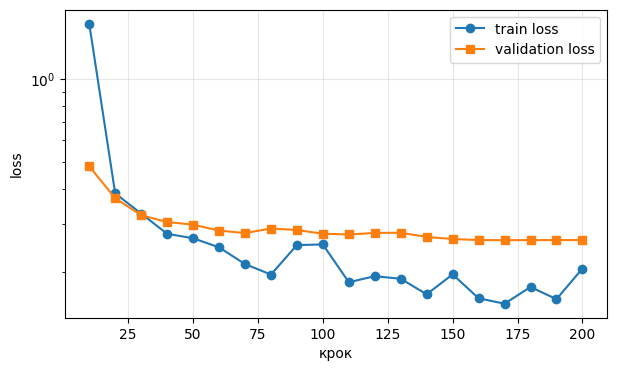

In [ ]:
log = trainer.state.log_history
train_loss = {h["step"]: h["loss"] for h in log if "loss" in h}
val_loss = {h["step"]: h["eval_loss"] for h in log if "eval_loss" in h}
steps = sorted(set(train_loss) | set(val_loss))
loss_table = pd.DataFrame({"крок": steps,
                           "train loss": [train_loss.get(s) for s in steps],
                           "val loss": [val_loss.get(s) for s in steps]})
display(loss_table.round(4))

plt.figure(figsize=(7, 4))
plt.plot(list(train_loss), list(train_loss.values()), marker="o", label="train loss")
plt.plot(list(val_loss), list(val_loss.values()), marker="s", label="validation loss")
plt.xlabel("крок")
plt.ylabel("loss")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 1.5. До і після донавчання

### 1.5.1. Порівняння

In [ ]:
ft_model = trainer.model
after_metrics, after_records = evaluate(ft_model, SHORT_PROMPT, test_examples)
after_manual_metrics, after_manual_records = evaluate(ft_model, SHORT_PROMPT, manual_examples)

comparison = pd.DataFrame({
    "до, тестовий": before_metrics,
    "після, тестовий": after_metrics,
    "до, ручний": before_manual_metrics,
    "після, ручний": after_manual_metrics,
})

display(comparison.round(1))

,"до, тестовий","після, тестовий","до, ручний","після, ручний"
"Чистий SQL, %",99.8,100.0,100.0,100.0
"Валідний SQL за схемою, %",79.0,85.8,100.0,95.0
"Exact match, %",19.8,40.2,55.0,70.0
"Exact match: JOIN, %",0.0,7.8,0.0,40.0
"Exact match: GROUP BY, %",5.3,24.8,20.0,80.0
"Exact match: HAVING, %",3.0,21.2,0.0,100.0
"Exact match: ORDER BY, %",21.6,41.4,100.0,80.0
"Exact match: LIMIT, %",16.1,25.8,100.0,100.0
"Exact match: вкладений запит, %",31.2,43.8,50.0,50.0
"Exact match: UNION / INTERSECT / EXCEPT, %",15.9,18.2,0.0,0.0


### 1.5.2. Відповіді

In [ ]:
for before, after in list(zip(before_records, after_records))[:8]:
    print(f"База: {before['db_id']}")
    print(f"Схема:\n{format_schema(before['schema'])}")
    print(f"Питання: {before['question']}")
    print(f"Еталон: {before['target']}")
    print(f"До:    {before['answer']}  {'OK' if is_exact(before) else 'FAIL'}")
    print(f"Після: {after['answer']}  {'OK' if is_exact(after) else 'FAIL'}")
    print("-" * 60)

База: aircraft
Схема:
  pilot:
    - Pilot_Id (number)
    - Name (text)
    - Age (number)
  aircraft:
    - Aircraft_ID (number)
    - Aircraft (text)
    - Description (text)
    - Max_Gross_Weight (text)
    - Total_disk_area (text)
    - Max_disk_Loading (text)
  match:
    - Round (number)
    - Location (text)
    - Country (text)
    - Date (text)
    - Fastest_Qualifying (text)
    - Winning_Pilot (text)
    - Winning_Aircraft (text)
  airport:
    - Airport_ID (number)
    - Airport_Name (text)
    - Total_Passengers (number)
    - %_Change_2007 (text)
    - International_Passengers (number)
    - Domestic_Passengers (number)
    - Transit_Passengers (number)
    - Aircraft_Movements (number)
    - Freight_Metric_Tonnes (number)
  airport_aircraft:
    - ID (number)
    - Airport_ID (number)
    - Aircraft_ID (number)
Питання: Please list the location and the winning aircraft name.
Еталон: SELECT T2.Location , T1.Aircraft FROM aircraft AS T1 JOIN MATCH AS T2 ON T1.Aircraft_ID

### 1.5.3. Аналіз помилок після донавчання

In [ ]:
def error_table(records):
    rows = []
    for r in records:
        if is_exact(r):
            continue
        if r["parsed"] is None:
            kind = "порожня відповідь"
        elif not is_valid(r):
            kind = "невалідний SQL"
        else:
            kind = "валідний SQL, але не збігається з еталоном"
        rows.append({"тип помилки": kind, "база": r["db_id"], "схема": r["schema"],
                     "питання": r["question"], "еталон": r["target"], "відповідь": r["answer"]})
    return pd.DataFrame(rows)

errors = error_table(after_records)
bad = [r for r in after_records if not is_exact(r)]
if len(errors):
    display(errors["тип помилки"].value_counts().to_frame("кількість"))
    display(errors.groupby("тип помилки").head(10))

,кількість
тип помилки,
"валідний SQL, але не збігається з еталоном",228
невалідний SQL,71


,тип помилки,база,схема,питання,еталон,відповідь
0,"валідний SQL, але не збігається з еталоном",aircraft,"pilot: Pilot_Id (number), Name (text), Age (nu...",Please list the location and the winning aircr...,"SELECT T2.Location , T1.Aircraft FROM aircraft...","SELECT LOCATION , Winning_Aircraft FROM match"
1,"валідний SQL, але не збігається з еталоном",music_1,"genre: g_name (text), rating (text), most_popu...",Find the name and country of origin for all ar...,"SELECT T1.artist_name , T1.country FROM artist...","SELECT T1.artist_name , T1.country FROM artist..."
2,"валідний SQL, але не збігається з еталоном",tracking_grants_for_research,"Document_Types: document_type_code (text), doc...",What is the type of the document whose descrip...,SELECT document_type_code FROM Document_Types ...,SELECT document_type_code FROM document_types ...
3,"валідний SQL, але не збігається з еталоном",music_1,"genre: g_name (text), rating (text), most_popu...",Find the names and number of works of all arti...,"SELECT T1.artist_name , count(*) FROM artist A...","SELECT T1.artist_name , count(*) FROM song AS ..."
4,"валідний SQL, але не збігається з еталоном",student_assessment,"Addresses: address_id (number), line_1 (text),...",what is id of students who registered some cou...,SELECT student_id FROM student_course_registra...,SELECT T1.student_id FROM Student_Course_Regis...
5,невалідний SQL,tracking_grants_for_research,"Document_Types: document_type_code (text), doc...","What are the task details, task ids, and proje...","SELECT T1.task_details , T1.task_id , T2.proje...","SELECT task_details , task_id , project_id FRO..."
6,"валідний SQL, але не збігається з еталоном",tracking_grants_for_research,"Document_Types: document_type_code (text), doc...",When did the first staff member start working?,SELECT date_from FROM Project_Staff ORDER BY d...,SELECT date_from FROM project_staff ORDER BY d...
7,"валідний SQL, але не збігається з еталоном",climbing,"mountain: Mountain_ID (number), Name (text), H...",Give the names of mountains in alphabetical or...,SELECT Name FROM mountain ORDER BY Name ASC,SELECT Name FROM mountain ORDER BY Name
8,"валідний SQL, але не збігається з еталоном",theme_gallery,"artist: Artist_ID (number), Name (text), Count...",Return the names of artists and the themes of ...,"SELECT T1.theme , T2.name FROM exhibition AS T...","SELECT T1.Name , T2.Theme FROM artist AS T1 JO..."
9,невалідний SQL,tracking_grants_for_research,"Document_Types: document_type_code (text), doc...",What roles did staff members play between '200...,SELECT role_code FROM Project_Staff WHERE date...,SELECT role_code FROM staff_roles AS T1 JOIN p...


In [ ]:
print("Помилкові відповіді на тестовому наборі:\n")
show_records(bad, k=10)

Помилкові відповіді на тестовому наборі:

База: aircraft
Схема:
  pilot:
    - Pilot_Id (number)
    - Name (text)
    - Age (number)
  aircraft:
    - Aircraft_ID (number)
    - Aircraft (text)
    - Description (text)
    - Max_Gross_Weight (text)
    - Total_disk_area (text)
    - Max_disk_Loading (text)
  match:
    - Round (number)
    - Location (text)
    - Country (text)
    - Date (text)
    - Fastest_Qualifying (text)
    - Winning_Pilot (text)
    - Winning_Aircraft (text)
  airport:
    - Airport_ID (number)
    - Airport_Name (text)
    - Total_Passengers (number)
    - %_Change_2007 (text)
    - International_Passengers (number)
    - Domestic_Passengers (number)
    - Transit_Passengers (number)
    - Aircraft_Movements (number)
    - Freight_Metric_Tonnes (number)
  airport_aircraft:
    - ID (number)
    - Airport_ID (number)
    - Aircraft_ID (number)
Питання: Please list the location and the winning aircraft name.
Еталон: SELECT T2.Location , T1.Aircraft FROM aircraf

### 1.5.4. Аналіз виправлень після донавчання

In [ ]:
def compare_errors(before_records, after_records):
    rows = []

    for before, after in zip(before_records, after_records):
        before_ok = is_exact(before)
        after_ok = is_exact(after)

        if not before_ok and after_ok:
            status = "FAIL → OK"
        elif before_ok and not after_ok:
            status = "OK → FAIL"
        elif not before_ok and not after_ok:
            status = "FAIL → FAIL"
        else:
            status = "OK → OK"

        rows.append({
            "результат": status,
            "база": before["db_id"],
            "схема": before["schema"],
            "питання": before["question"],
            "еталон": before["target"],
            "стара модель": before["answer"],
            "нова модель": after["answer"]
        })

    return pd.DataFrame(rows)


comparison_errors = compare_errors(
    before_records,
    after_records
)

fixed = comparison_errors[
    comparison_errors["результат"] == "FAIL → OK"
]


def show_fixed_records(records, k=10):
    for _, r in records.head(k).iterrows():
        print(
            f"База: {r['база']}\n"
            f"Схема:\n{format_schema(r['схема'])}\n"
            f"Питання: {r['питання']}\n"
            f"Еталон: {r['еталон']}\n"
            f"Стара модель: {r['стара модель']}\n"
            f"Нова модель: {r['нова модель']}  OK\n"
            + "-" * 60
        )


print("Виправлені відповіді донавченою моделлю:\n")
show_fixed_records(fixed, k=50)

Виправлені відповіді донавченою моделлю:

База: theme_gallery
Схема:
  artist:
    - Artist_ID (number)
    - Name (text)
    - Country (text)
    - Year_Join (number)
    - Age (number)
  exhibition:
    - Exhibition_ID (number)
    - Year (number)
    - Theme (text)
    - Artist_ID (number)
    - Ticket_Price (number)
  exhibition_record:
    - Exhibition_ID (number)
    - Date (text)
    - Attendance (number)
Питання: Show the average, minimum, and maximum ticket prices for exhibitions for all years before 2009.
Еталон: SELECT avg(ticket_price) , min(ticket_price) , max(ticket_price) FROM exhibition WHERE YEAR < 2009
Стара модель: SELECT AVG(Ticket_Price), MIN(Ticket_Price), MAX(Ticket_Price) FROM exhibition WHERE Year < 2009
Нова модель: SELECT avg(Ticket_Price) , min(Ticket_Price) , max(Ticket_Price) FROM exhibition WHERE YEAR < 2009  OK
------------------------------------------------------------
База: climbing
Схема:
  mountain:
    - Mountain_ID (number)
    - Name (text)
    -

### 1.5.5. Загальні запити після донавчання

In [ ]:
general_after = generate_batch(ft_model, general_conversations, max_new_tokens=500)
for q, before, after in zip(GENERAL_QUESTIONS, general_before, general_after):
    print(f"Питання: {q}\nДо:\n{before}\nПісля:\n{after}\n" + "=" * 60)

Питання: Поясни простими словами, що таке фотосинтез.
До:
Фотосинтез — це процес, який росливи і тварини виконують, щоб створити їхній їжі і енергію. Це дуже важливе для землі, бо без фотосинтезу не може жити жодна рослина і тварина.

### Як це робиться?

1. **Під час сонця**: Рослини і тварини використовують сонячну енергію, щоб відновити свої ресурси.

2. **Під час фотосинтезу**: 
   - Рослини використовують **світло** (з сонця).
   - Вони використовують **воду** (з землі) і **кисень** (з повітря).
   - Вони відтворюють **загоюсти** (наприклад, глюкозу) і **електрони** (які дадуть енергію).

3. **Енергія**: Від цього процесу рослини відтворюють **електричну енергію**, яку вони використовують для росту і роботи.

### Що відбувається?

- **Воду** з землі відновлюється.
- **Кисень** з повітря відновлюється.
- **Глюкозу** і **електрони** створюються.
- **Енергія** від цього процесу використовується для росту і роботи.

### Заключення:

Фотосинтез — це процес, який рослини і тварини викон

## 1.6. Мій звіт

### 1.6.1. Задача і чому потрібне донавчання
Ціллю є автоматичне перетворення тексту природною мовою на SQL-запити з урахуванням схеми конкретної бази даних. Донавчання потрібне, щоб модель краще зіставляла формулювання питання з таблицями та колонками, правильно будувала зв'язки між таблицями `JOIN`, агрегування `GROUP BY` та `HAVING`, сортування, обмеження кількості результатів, вкладені запити та операції `UNION` / `INTERSECT` / `EXCEPT`. Також важливо, щоб модель використовувала тільки об'єкти, наявні в переданій схемі, і повертала SQL без зайвих пояснень. Додатковою перевагою є зменшення системного промпту.

### 1.6.2. Модель і дані

Використано `Qwen/Qwen3-1.7B` на 1,72 млрд параметрів. Вона компактна порівняно з великими мовними моделями, тому її можна донавчати на доступній GPU, а задача Text-to-SQL має чіткий контекст: схема БД, питання та очікуваний SQL.\
Основний набір даних - підготований датасет Spider `SuperMax991/spider-text2sql`, спліт `train`.\
Ліцензія: `Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0)`.\
Розділення виконано за `db_id` - бази даних між train, validation і test не перетинаються.
\
Окремо використано вручну сформовані контрольних питань до двох власних схем - `pc_shop` та `library`.

### 1.6.3. Метрика й результат до донавчання
Основні показники - `Exact Match`, валідність SQL за схемою та частка відповідей, що містять чистий SQL.\
`Exact Match` перевіряє збіг нормалізованого запиту з еталоном. Перевірка валідності виконує SQL через SQLite `EXPLAIN` на тимчасовій структурі таблиць і колонок зі схеми. Перевіряєьтся синтаксична та структурна сумісність.\
Найбільша проблема до донавчання - запити з `JOIN`, агрегування та `HAVING`.

| Метрика | Тестовий, % | Ручний, % |
|---|---:|---:|
| Чистий SQL | 99.8 | 100.0 |
| Валідний SQL за схемою | 79.0 | 100.0 |
| Exact Match | 19.8 | 55.0 |
| Exact match: простий | 38.7 | 83.3 |
| Exact match: JOIN | 0.0 | 0.0 |
| Exact match: GROUP BY | 5.3 | 20.0 |
| Exact match: HAVING | 3.0 | 0.0 |
| Exact match: ORDER BY | 21.6 | 100.0 |
| Exact match: LIMIT | 16.1 | 100.0 |
| Exact match: вкладений запит | 31.2 | 50.0 |
| Exact match: UNION / INTERSECT / EXCEPT | 15.9 | 0.0 |

### 1.6.4. Метод донавчання та гіперпараметри

Для донавчання моделі використано метод Supervised Fine-Tuning із застосуванням адаптерів LoRA. Такий підхід дозволяє адаптувати попередньо навчену модель до задачі Text-to-SQL без повного оновлення всіх її параметрів. Замість цього навчаються додаткові низькорангові матриці, що зменшує обчислювальні витрати та потребу у відеопам'яті GPU.

Метод обрано через відносно невеликий розмір базової моделі та доступні обчислювальні ресурси. LoRA забезпечує достатню гнучкість для адаптації моделі до формування SQL-запитів, водночас не потребуючи повного донавчання всіх параметрів.

Для навчання використано такі гіперпараметри:

| Гіперпараметр | Значення | Призначення |
|---|---:|---|
| `r` | 16 | Ранг LoRA-адаптерів, визначає їхню ємність |
| `lora_alpha` | 32 | Коефіцієнт масштабування впливу LoRA-адаптерів |
| `lora_dropout` | 0.05 | Регуляризація для зменшення ризику перенавчання |
| `target_modules` | `all-linear` | Застосування адаптерів до всіх лінійних шарів |
| `learning_rate` | 2e-4 | Швидкість оновлення параметрів адаптерів |
| `max_steps` | 200 | Загальна кількість кроків оптимізації |
| `per_device_train_batch_size` | 2 | Кількість прикладів в одному мікробатчі |
| `gradient_accumulation_steps` | 4 | Кількість кроків накопичення градієнтів |
| `max_length` | 1024 | Максимальна довжина послідовності токенів |
| `fp16` | True | Використання обчислень у форматі половинної точності |
| `assistant_only_loss` | True | Обчислення функції втрат лише для відповідей асистента |

Обґрунтування гіперпараметрів:
- `Learning rate = 2e-4` обрано для забезпечення швидкої адаптації LoRA-параметрів без надмірно великих оновлень ваг.
- `Кількість кроків = 200` ефективно адаптує модель до формату Text-to-SQL. З більшою кількістю кроків якість моделі майже не покращується, проте спостерігаються значні ознаки overfitting.
- `Batch size = 2` дозволяє зменшити використання відеопам'яті. Ефективний розмір батча становить 8 прикладів.
- `LoRA rank = 16` забезпечує достатню кількість додаткових параметрів для адаптації моделі до нової задачі, не створюючи надмірного обчислювального навантаження.
- `LoRA alpha = 32` співвідношення `alpha/r = 2` забезпечує відповідний масштаб адаптації.
- `LoRA dropout = 0.05` використовується для зменшення ризику перенавчання.
- `gradient checkpointing` застосовується для зменшення використання відеопам'яті GPU під час навчання.
- `FP16` використовується, так як T4 GPU не підтримує `BF16`.

Результати навчання:
- Тривалість тренування: `16.644 хв`.
- Пікове використання пам'яті GPU: `4.247 GB`.
- Показник Validation Loss: `0.262`.

Графік Training/Validation Loss:



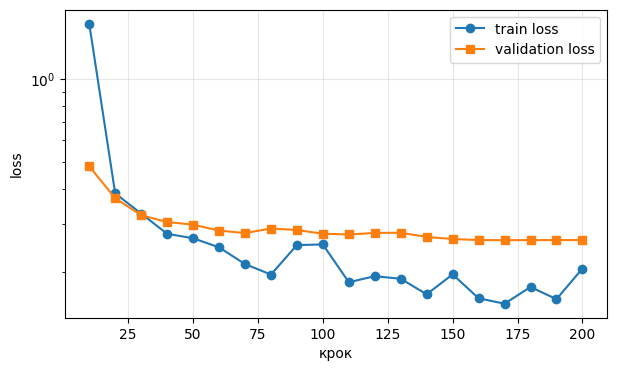

In [ ]:
print("Графік Training/Validation Loss:\n")
plt.figure(figsize=(7, 4))
plt.plot(list(train_loss), list(train_loss.values()), marker="o", label="train loss")
plt.plot(list(val_loss), list(val_loss.values()), marker="s", label="validation loss")
plt.xlabel("крок")
plt.ylabel("loss")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 1.6.5. Результат після донавчання

На тестовому наборі:
- `Exact Match`: 19.8% → 41.2%.
- Валідність SQL за схемою: 79.0% → 86.6%.
- Частка чистого SQL: 99.8% → 100.0%.

На ручному наборі:
- `Exact Match`: 55.0% → 70.0%.
- Для простих запитів (38.7% → 72.3%).
- `GROUP BY` (5.3% → 26.3%).
- `HAVING` (3.0% → 21.2%).
- `JOIN` (0.0% → 8.3%).

| Метрика | Тест до, % | Тест після, % | Ручний до, % | Ручний після, % |
|---|---:|---:|---:|---:|
| Чистий SQL | 99.8 | 100.0 | 100.0 | 100.0 |
| Валідний SQL за схемою | 79.0 | 86.6 | 100.0 | 95.0 |
| Exact Match | 19.8 | 41.2 | 55.0 | 70.0 |
| Exact match: простий | 38.7 | 72.3 | 83.3 | 83.3 |
| Exact match: JOIN | 0.0 | 8.3 | 0.0 | 40.0 |
| Exact match: GROUP BY | 5.3 | 26.3 | 20.0 | 80.0 |
| Exact match: HAVING | 3.0 | 21.2 | 0.0 | 100.0 |
| Exact match: ORDER BY | 21.6 | 45.1 | 100.0 | 80.0 |
| Exact match: LIMIT | 16.1 | 31.2 | 100.0 | 100.0 |
| Exact match: вкладений запит | 31.2 | 43.8 | 50.0 | 50.0 |
| Exact match: UNION / INTERSECT / EXCEPT | 15.9 | 18.2 | 0.0 | 0.0 |

### 1.6.6. Аналіз відповідей моделі

#### Аналіз покращень

**Приклад 1. Виправлення JOIN та вибору таблиці з іменами**

Демонструється суттєве покращення розуміння структури реляційної бази даних. Стара модель не врахувала, що імена бодібілдерів зберігаються в таблиці `people`, а результати виступів - у таблиці `body_builder`. Натомість вона намагалася отримати ім'я безпосередньо з таблиці результатів.

**Схема:**
```sql
body_builder:
  Body_Builder_ID (number)
  People_ID (number)
  Snatch (number)
  Clean_Jerk (number)
  Total (number)

people:
  People_ID (number)
  Name (text)
  Height (number)
  Weight (number)
  Birth_Date (text)
  Birth_Place (text)
```

**Питання:** What are the names of body builders in descending order of total scores?

**Еталон:**
```sql
SELECT T2.Name
FROM body_builder AS T1
JOIN people AS T2 ON T1.People_ID = T2.People_ID
ORDER BY T1.Total DESC
```

**До донавчання:**
```sql
SELECT Name FROM body_builder ORDER BY Total DESC
```

**Після донавчання:**
```sql
SELECT T2.Name
FROM body_builder AS T1
JOIN people AS T2 ON T1.People_ID = T2.People_ID
ORDER BY T1.Total DESC
```

**Результат:** стара модель сформувала запит із неправильною таблицею для отримання імені. Нова модель повністю відтворила еталонний SQL-запит: правильно об'єднала таблиці за `People_ID`, отримала імена з таблиці `people` та відсортувала результати за загальним балом у спадному порядку.

**Висновок:** донавчання моделі виправило не лише синтаксис, а й принципове розуміння структури баз даних і зв'язків між таблицями.

---
**Приклад 2. Виправлення логіки JOIN та умов відбору**

Демонструється покращення здатності моделі інтерпретувати природномовне питання та знаходити інформацію, розподілену між декількома таблицями. Стара модель неправильно використала поле `preferred_genre` замість мови виконання пісні та не врахувала необхідність об'єднання таблиць `artist` і `song`.

**Схема:**
```sql
artist:
  artist_name (text)
  country (text)
  gender (text)
  preferred_genre (text)

song:
  song_name (text)
  artist_name (text)
  country (text)
  f_id (number)
  genre_is (text)
  rating (number)
  languages (text)
  releasedate (time)
  resolution (number)
```

**Питання:** What is the country of origin of the artist who is female and produced a song in Bangla?

**Еталон:**
```sql
SELECT T1.country
FROM artist AS T1
JOIN song AS T2 ON T1.artist_name = T2.artist_name
WHERE T1.gender = "Female"
AND T2.languages = "bangla"
```

**До донавчання:**
```sql
SELECT artist_name, country
FROM artist
WHERE gender = 'female'
AND preferred_genre = 'Bangla'
```

**Після донавчання:**
```sql
SELECT T1.country
FROM artist AS T1
JOIN song AS T2 ON T1.artist_name = T2.artist_name
WHERE T1.gender = "female"
AND T2.languages = "Bangla"
```

**Результат:** стара модель неправильно інтерпретувала умову про пісню мовою Bangla як умову щодо улюбленого жанру виконавця. Нова модель правильно визначила необхідність об'єднання двох таблиць за іменем виконавця, перевірила стать у таблиці `artist`, а мову пісні - у таблиці `song`. Також вона повернула саме країну походження виконавця, як вимагалося в запитанні.

**Висновок:** донавчання дозволило виправити декілька семантичних помилок: вибір таблиць, атрибутів, умови JOIN та стовпців.

#### Аналіз помилок

**Приклад 1. Неправильна реалізація складної умови з агрегуванням**

**Питання:** What are the task details, task ids, and project ids for the progrects that are detailed as 'omnis' or have at least 3 outcomes?

**Еталон:**
```sql
SELECT T1.task_details, T1.task_id, T2.project_id
FROM Tasks AS T1
JOIN Projects AS T2 ON T1.project_id = T2.project_id
WHERE T2.project_details = 'omnis'
UNION
SELECT T1.task_details, T1.task_id, T2.project_id
FROM Tasks AS T1
JOIN Projects AS T2 ON T1.project_id = T2.project_id
JOIN Project_outcomes AS T3 ON T2.project_id = T3.project_id
GROUP BY T2.project_id
HAVING count(*) > 2
```

**Відповідь донавченої моделі:**
```sql
SELECT task_details, task_id, project_id
FROM Tasks
WHERE project_id IN (
    SELECT project_id
    FROM Projects
    WHERE project_details = 'omnis' OR count(*) >= 3
)
```

**Результат:** модель неправильно реалізувала умову щодо проєктів, які мають щонайменше три результати. Вона використала `COUNT(*)` без групування та об'єднання з таблицею `Project_Outcomes`. Агрегатна функція була розміщена безпосередньо в умові `WHERE`, що робить запит некоректним для поставленого завдання. Еталон використовує `UNION` для об'єднання результатів двох незалежних критеріїв.

**Висновок:** навіть після донавчання, модель має складнощі з побудовою складних підзапитів, агрегуванням та комбінуванням альтернативних умов.

---
**Приклад 2. Неправильний порядок вибору стовпців**

**Питання:** Return the names of artists and the themes of their exhibitions that had a ticket price higher than average.

**Еталон:**
```sql
SELECT T1.theme, T2.name
FROM exhibition AS T1
JOIN artist AS T2 ON T1.artist_id = T2.artist_id
WHERE T1.ticket_price > (
    SELECT avg(ticket_price)
    FROM exhibition
)
```

**Відповідь донавченої моделі:**
```sql
SELECT T1.Name, T2.Theme
FROM artist AS T1
JOIN exhibition AS T2 ON T1.Artist_ID = T2.Artist_ID
WHERE T2.Ticket_Price > (
    SELECT avg(Ticket_Price)
    FROM exhibition
)
```

**Результат:** модель правильно визначила необхідність об'єднання таблиць `artist` та `exhibition`, а також коректно реалізувала підзапит для обчислення середньої вартості квитка. Проте вона переплутала порядок стовпців у фінальній вибірці: замість теми виставки та імені художника повернула ім'я художника та тему виставки. Умова фільтрації при цьому залишилася правильною.

**Висновок:** модель правильно розуміє зв'язки між таблицями та умови відбору, але може припускатися помилок під час формування `SELECT`.

### 1.6.7. Висновок

В ході виконання лабораторної роботи було виконано донавчання моделі `Qwen3-1.7B` для перетворення тексту природною мовою на SQL-запити за допомогою методу `LoRA`.\
В результаті вдалося покращити якість генерації SQL-запитів: `Exact Match` на тестовому наборі зріс з `19,8%` до `41,2%`, а на власних прикладах - з `55%` до `70%`.\
Покращилася правильність формування запитів із `JOIN`, `GROUP BY` та `HAVING`. Модель навчилася краще враховувати структуру бази даних і використовувати її таблиці та колонки. Водночас деякі складні конструкції, зокрема `UNION`, `INTERSECT` та `EXCEPT`, залишаються проблемними. Загалом, донавчання дозволило суттєво покращити роботу моделі з SQL-запитами, використовуючи відносно малі обчислювальні ресурси.